In [1]:
import os
import time
import psutil
import warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

warnings.filterwarnings('ignore')

def get_current_ram_gb():
    """Lấy lượng RAM hiện tại tiến trình Python đang chiếm dụng (GB)"""
    return psutil.Process(os.getpid()).memory_info().rss / (1024 ** 3)

def calc_ks(y_true, y_pred):
    """Tính toán chỉ số Kolmogorov-Smirnov (KS)"""
    return ks_2samp(y_pred[y_true == 1], y_pred[y_true == 0]).statistic * 100

def evaluate_models_v2_optimized(file_path: str, n_splits: int = 5):
    print("=" * 85)
    print(f"📂 [V2 OPTIMIZED - ENSEMBLE CỐ ĐỊNH 50-50]: {file_path}")
    print("=" * 85)

    if not os.path.exists(file_path):
        print(f"❌ Lỗi: Không tìm thấy file dữ liệu tại '{file_path}'")
        return None

    df = pd.read_parquet(file_path) if file_path.endswith('.parquet') else pd.read_csv(file_path)

    n_rows, n_cols = df.shape
    dataset_ram_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

    target_col = 'TARGET'
    ignore_cols = ['SK_ID_CURR', target_col]
    X = df.drop(columns=[col for col in ignore_cols if col in df.columns])
    y = df[target_col]

    # Chuẩn hóa biến Categorical cho GBDT
    cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
    for col in cat_cols:
        X[col] = X[col].astype('category')

    # 1. THAM SỐ ĐÃ TỐI ƯU
    lgb_params = {
        'objective': 'binary',
        'metric': 'auc',
        'boosting_type': 'gbdt',
        'learning_rate': 0.0218,
        'num_leaves': 54,
        'max_depth': 7,
        'min_child_samples': 87,
        'colsample_bytree': 0.6048,
        'subsample': 0.8906,
        'subsample_freq': 1,
        'reg_alpha': 5.7108,
        'reg_lambda': 0.0581,
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }

    xgb_params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'tree_method': 'hist',
        'enable_categorical': True,
        'learning_rate': 0.0245,
        'max_depth': 9,
        'min_child_weight': 160,
        'colsample_bytree': 0.8349,
        'subsample': 0.9237,
        'reg_alpha': 0.6219,
        'reg_lambda': 5.8294,
        'random_state': 42,
        'n_jobs': -1
    }

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    lgb_oof = np.zeros(len(X))
    xgb_oof = np.zeros(len(X))

    lgb_tr_aucs, lgb_va_aucs = [], []
    xgb_tr_aucs, xgb_va_aucs = [], []
    lgb_latencies, xgb_latencies = [], []

    peak_ram_lgb = get_current_ram_gb()
    peak_ram_xgb = get_current_ram_gb()
    time_lgb_total = 0.0
    time_xgb_total = 0.0

    print(f"⚡ Đang chạy {n_splits}-Fold Cross Validation...")

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        # --- Train LightGBM ---
        t0_lgb = time.time()
        model_lgb = lgb.LGBMClassifier(**lgb_params, n_estimators=3000)
        model_lgb.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=60, verbose=False)]
        )
        time_lgb_total += (time.time() - t0_lgb)
        peak_ram_lgb = max(peak_ram_lgb, get_current_ram_gb())

        lgb_tr_pred = model_lgb.predict_proba(X_tr)[:, 1]

        t0_inf = time.time()
        lgb_va_pred = model_lgb.predict_proba(X_va)[:, 1]
        lgb_latencies.append(((time.time() - t0_inf) / len(X_va)) * 1000)
        lgb_oof[val_idx] = lgb_va_pred

        # --- Train XGBoost ---
        t0_xgb = time.time()
        model_xgb = xgb.XGBClassifier(**xgb_params, n_estimators=3000, early_stopping_rounds=60)
        model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        time_xgb_total += (time.time() - t0_xgb)
        peak_ram_xgb = max(peak_ram_xgb, get_current_ram_gb())

        xgb_tr_pred = model_xgb.predict_proba(X_tr)[:, 1]

        t0_inf = time.time()
        xgb_va_pred = model_xgb.predict_proba(X_va)[:, 1]
        xgb_latencies.append(((time.time() - t0_inf) / len(X_va)) * 1000)
        xgb_oof[val_idx] = xgb_va_pred

        # --- Ghi nhận metric ---
        lgb_tr_auc = roc_auc_score(y_tr, lgb_tr_pred)
        lgb_va_auc = roc_auc_score(y_va, lgb_va_pred)
        lgb_tr_aucs.append(lgb_tr_auc)
        lgb_va_aucs.append(lgb_va_auc)

        xgb_tr_auc = roc_auc_score(y_tr, xgb_tr_pred)
        xgb_va_auc = roc_auc_score(y_va, xgb_va_pred)
        xgb_tr_aucs.append(xgb_tr_auc)
        xgb_va_aucs.append(xgb_va_auc)

        print(f"   ▫️ Fold {fold} | LGB Val: {lgb_va_auc:.5f} (Gap: {lgb_tr_auc - lgb_va_auc:+.5f}) | XGB Val: {xgb_va_auc:.5f} (Gap: {xgb_tr_auc - xgb_va_auc:+.5f})")

    # =========================================================================
    # 2. CHỐT CỐ ĐỊNH TỶ LỆ ENSEMBLE 50% - 50%
    # =========================================================================
    w_lgb = 0.5
    w_xgb = 0.5
    opt_ensemble_oof = 0.5 * lgb_oof + 0.5 * xgb_oof

    ens_tr_aucs = []
    ens_va_aucs = []
    for f in range(n_splits):
        tr_pred_ens = 0.5 * lgb_tr_aucs[f] + 0.5 * xgb_tr_aucs[f]
        va_pred_ens = 0.5 * lgb_va_aucs[f] + 0.5 * xgb_va_aucs[f]
        ens_tr_aucs.append(tr_pred_ens)
        ens_va_aucs.append(va_pred_ens)

    lgb_auc = roc_auc_score(y, lgb_oof)
    xgb_auc = roc_auc_score(y, xgb_oof)
    opt_ens_auc = roc_auc_score(y, opt_ensemble_oof)

    print("\n" + "=" * 60)
    print("🏆 KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC (OOF ROC-AUC - ENSEMBLE 50-50)")
    print("=" * 60)
    print(f"🔹 LightGBM (Tuned)       : {lgb_auc:.5f}")
    print(f"🔹 XGBoost (Tuned)        : {xgb_auc:.5f}")
    print(f"🥇 Ensemble Blend (50:50) : {opt_ens_auc:.5f}")
    print("=" * 60)

    # 3. HIỂN THỊ BẢNG ĐỐI CHỨNG
    lgb_gaps = np.array(lgb_tr_aucs) - np.array(lgb_va_aucs)
    xgb_gaps = np.array(xgb_tr_aucs) - np.array(xgb_va_aucs)
    ens_gaps = np.array(ens_tr_aucs) - np.array(ens_va_aucs)

    models_eval = [
        ('LightGBM (Tuned)', lgb_auc, lgb_tr_aucs, lgb_va_aucs, lgb_gaps, lgb_oof, time_lgb_total, peak_ram_lgb, np.mean(lgb_latencies)),
        ('XGBoost (Tuned)', xgb_auc, xgb_tr_aucs, xgb_va_aucs, xgb_gaps, xgb_oof, time_xgb_total, peak_ram_xgb, np.mean(xgb_latencies)),
        ('Ensemble Blend (50:50)', opt_ens_auc, ens_tr_aucs, ens_va_aucs, ens_gaps, opt_ensemble_oof, time_lgb_total + time_xgb_total, max(peak_ram_lgb, peak_ram_xgb), np.mean(lgb_latencies) + np.mean(xgb_latencies))
    ]

    perf_records = []
    res_records = []

    for name, main_auc, tr_list, va_list, gaps, oof_preds, t_run, p_ram, lat in models_eval:
        perf_records.append({
            'Model': name,
            'ROC-AUC (OOF)': f"{main_auc:.5f}",
            'Fold AUC (Mean ± Std)': f"{np.mean(va_list):.5f} ± {np.std(va_list):.5f}",
            'Train AUC': f"{np.mean(tr_list):.5f}",
            'Overfit Gap': f"{np.mean(gaps):.5f} ± {np.std(gaps):.5f}",
            'Gini (%)': f"{(2 * main_auc - 1) * 100:.2f}%",
            'KS (%)': f"{calc_ks(y, oof_preds):.2f}%"
        })

        res_records.append({
            'Model': name,
            'Training Time': f"{t_run:.1f} s",
            'Peak RAM': f"{p_ram:.2f} GB",
            'Inference Latency': f"{lat:.4f} ms/sample"
        })

    print("\n📊 BẢNG 1: CHỈ SỐ RỦI RO TÍN DỤNG CHÍNH THỨC (ENSEMBLE 50-50)")
    display(pd.DataFrame(perf_records))

    print("\n⚙️ BẢNG 2: TIÊU HAO TÀI NGUYÊN")
    display(pd.DataFrame(res_records))

    print(f"\n📌 Thông số tập dữ liệu: {n_rows:,} dòng | {X.shape[1]} đặc trưng | RAM: {dataset_ram_mb:.1f} MB")

    return {
        'df': df,
        'y': y,
        'lgb_oof': lgb_oof,
        'xgb_oof': xgb_oof,
        'opt_ensemble_oof': opt_ensemble_oof,
        'weights': (0.5, 0.5)
    }

# THỰC THI HUẤN LUYỆN
data_path = '/Users/nguyenminhtri/FinalYearPro/data/processed/df_train_fair_compliant.parquet'
eval_output = evaluate_models_v2_optimized(file_path=data_path, n_splits=5)

📂 [V2 OPTIMIZED - ENSEMBLE CỐ ĐỊNH 50-50]: /Users/nguyenminhtri/FinalYearPro/data/processed/df_train_fair_compliant.parquet
⚡ Đang chạy 5-Fold Cross Validation...
   ▫️ Fold 1 | LGB Val: 0.78967 (Gap: +0.09339) | XGB Val: 0.79026 (Gap: +0.07450)
   ▫️ Fold 2 | LGB Val: 0.79799 (Gap: +0.09811) | XGB Val: 0.79761 (Gap: +0.06465)
   ▫️ Fold 3 | LGB Val: 0.78674 (Gap: +0.08521) | XGB Val: 0.78616 (Gap: +0.08394)
   ▫️ Fold 4 | LGB Val: 0.79451 (Gap: +0.10900) | XGB Val: 0.79523 (Gap: +0.06779)
   ▫️ Fold 5 | LGB Val: 0.78698 (Gap: +0.11053) | XGB Val: 0.78760 (Gap: +0.08463)

🏆 KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC (OOF ROC-AUC - ENSEMBLE 50-50)
🔹 LightGBM (Tuned)       : 0.79116
🔹 XGBoost (Tuned)        : 0.79133
🥇 Ensemble Blend (50:50) : 0.79226

📊 BẢNG 1: CHỈ SỐ RỦI RO TÍN DỤNG CHÍNH THỨC (ENSEMBLE 50-50)


,Model,ROC-AUC (OOF),Fold AUC (Mean ± Std),Train AUC,Overfit Gap,Gini (%),KS (%)
0,LightGBM (Tuned),0.79116,0.79118 ± 0.00441,0.89043,0.09925 ± 0.00954,58.23%,44.13%
1,XGBoost (Tuned),0.79133,0.79137 ± 0.00439,0.86647,0.07510 ± 0.00815,58.27%,44.25%
2,Ensemble Blend (50:50),0.79226,0.79127 ± 0.00439,0.87845,0.08718 ± 0.00567,58.45%,44.33%



⚙️ BẢNG 2: TIÊU HAO TÀI NGUYÊN


,Model,Training Time,Peak RAM,Inference Latency
0,LightGBM (Tuned),492.7 s,3.22 GB,0.0116 ms/sample
1,XGBoost (Tuned),1488.6 s,3.22 GB,0.0054 ms/sample
2,Ensemble Blend (50:50),1981.4 s,3.22 GB,0.0170 ms/sample



📌 Thông số tập dữ liệu: 307,511 dòng | 891 đặc trưng | RAM: 2112.3 MB


🎯 KẾT QUẢ TỐI ƯU HÓA NGƯỠNG CUT-OFF KINH DOANH (OOF SIMULATION, N=307,511):
🔹 Ngưỡng cắt tối ưu (T*)           : 16.0% (PD < 0.160)
🔹 Tỷ lệ phê duyệt danh mục        : 86.60%
🔹 Tỷ lệ nợ xấu danh mục kiểm soát  : 5.04%
🔹 Lợi nhuận ròng cực đại           : 17.24 Tỷ VNĐ


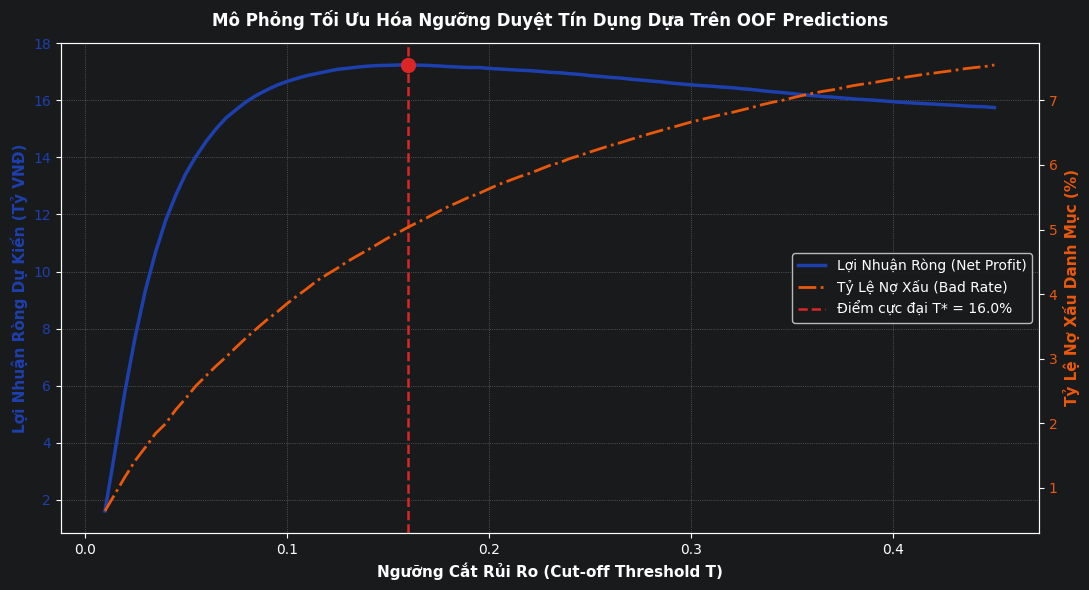

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. TRÍCH XUẤT DỮ LIỆU ĐÁNH GIÁ (OUT-OF-FOLD)
# ==============================================================================
probs_oof = eval_output['opt_ensemble_oof']
y_true = eval_output['y'].values
df_master = eval_output['df']

# Sử dụng giá trị khoản vay thực tế (AMT_CREDIT) hoặc fallback mặc định 100 triệu VNĐ
if 'AMT_CREDIT' in df_master.columns:
    loan_amounts = df_master['AMT_CREDIT'].values
else:
    loan_amounts = np.full(len(y_true), 100_000_000)

N_SAMPLES = len(y_true)

# ==============================================================================
# 2. THIẾT LẬP THAM SỐ TÀI CHÍNH VÀ LƯỚI QUÉT NGƯỠNG MỊN (STEP = 0.5%)
# ==============================================================================
INTEREST_RATE = 0.15   # Lãi ròng 15% trên giá trị khoản vay của khách trả tốt
LGD = 0.75             # Tổn thất khi vỡ nợ (Loss Given Default): Mất 75% khoản vay

# Quét từ 1.0% (0.01) đến 45.0% (0.45) với bước nhảy 0.5% (0.005) -> 89 bước quét
thresholds = np.arange(0.01, 0.455, 0.005)
sim_results = []

for T in thresholds:
    # Điều kiện duyệt vay: Xác suất vỡ nợ dự báo thấp hơn ngưỡng cắt T
    approved = (probs_oof < T)
    n_approved = np.sum(approved)

    if n_approved > 0:
        # Khách trả nợ tốt được duyệt: Sinh lãi
        good_mask = (y_true == 0) & approved
        total_profit = np.sum(loan_amounts[good_mask] * INTEREST_RATE)

        # Khách nợ xấu được duyệt: Tổn thất mất vốn (LGD)
        bad_mask = (y_true == 1) & approved
        total_loss = np.sum(loan_amounts[bad_mask] * LGD)

        net_profit = total_profit - total_loss
        bad_rate = (np.sum(bad_mask) / n_approved) * 100
        approval_rate = (n_approved / N_SAMPLES) * 100
    else:
        net_profit = 0.0
        bad_rate = 0.0
        approval_rate = 0.0

    sim_results.append({
        'Threshold': round(T, 4),
        'Threshold_Pct': f"{T * 100:.1f}%",
        'Approval_Rate': approval_rate,
        'Bad_Rate': bad_rate,
        'Net_Profit_Billion': net_profit / 1e9
    })

df_sim = pd.DataFrame(sim_results)

# Tìm ngưỡng T* mang lại lợi nhuận ròng cực đại
best_case = df_sim.loc[df_sim['Net_Profit_Billion'].idxmax()]

print("=" * 75)
print(f"🎯 KẾT QUẢ TỐI ƯU HÓA NGƯỠNG CUT-OFF KINH DOANH (OOF SIMULATION, N={N_SAMPLES:,}):")
print("=" * 75)
print(f"🔹 Ngưỡng cắt tối ưu (T*)           : {best_case['Threshold_Pct']} (PD < {best_case['Threshold']:.3f})")
print(f"🔹 Tỷ lệ phê duyệt danh mục        : {best_case['Approval_Rate']:.2f}%")
print(f"🔹 Tỷ lệ nợ xấu danh mục kiểm soát  : {best_case['Bad_Rate']:.2f}%")
print(f"🔹 Lợi nhuận ròng cực đại           : {best_case['Net_Profit_Billion']:,.2f} Tỷ VNĐ")
print("=" * 75)

# ==============================================================================
# 3. TRỰC QUAN HÓA ĐƯỜNG CONG ĐÁNH ĐỔI KINH DOANH (BUSINESS TRADE-OFF)
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(11, 6))

color_profit = '#1E40AF' # Xanh dương đậm
ax1.set_xlabel('Ngưỡng Cắt Rủi Ro (Cut-off Threshold T)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Lợi Nhuận Ròng Dự Kiến (Tỷ VNĐ)', color=color_profit, fontsize=11, fontweight='bold')
line1 = ax1.plot(df_sim['Threshold'], df_sim['Net_Profit_Billion'], color=color_profit, linewidth=2.5, label='Lợi Nhuận Ròng (Net Profit)')
ax1.axvline(x=best_case['Threshold'], color='#DC2626', linestyle='--', linewidth=1.8,
            label=f"Điểm cực đại T* = {best_case['Threshold_Pct']}")
ax1.scatter(best_case['Threshold'], best_case['Net_Profit_Billion'], color='#DC2626', s=100, zorder=5)
ax1.tick_params(axis='y', labelcolor=color_profit)
ax1.grid(True, linestyle=':', alpha=0.6)

# Trục thứ hai thể hiện tỷ lệ nợ xấu
ax2 = ax1.twinx()
color_bad = '#EA580C' # Cam cháy
ax2.set_ylabel('Tỷ Lệ Nợ Xấu Danh Mục (%)', color=color_bad, fontsize=11, fontweight='bold')
line2 = ax2.plot(df_sim['Threshold'], df_sim['Bad_Rate'], color=color_bad, linewidth=2, linestyle='-.', label='Tỷ Lệ Nợ Xấu (Bad Rate)')
ax2.tick_params(axis='y', labelcolor=color_bad)

# Gộp chú thích legend của 2 trục
lines = line1 + line2 + [ax1.get_lines()[-1]]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', framealpha=0.9)

plt.title('Mô Phỏng Tối Ưu Hóa Ngưỡng Duyệt Tín Dụng Dựa Trên OOF Predictions', fontsize=12, fontweight='bold', pad=12)
fig.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# KIỂM TRA SỐ LƯỢNG DÒNG CỦA PROBS_OOF VÀ TÍNH TOÀN VẸN DỮ LIỆU
# ==============================================================================
print("🔍 KIỂM TRA TÍNH TOÀN VẸN DỮ LIỆU OOF:")
print(f" • Kích thước mảng probs_oof       : {len(probs_oof):,} dòng")
print(f" • Kích thước nhãn thực tế y_true  : {len(y_true):,} dòng")
print(f" • Kích thước bảng gốc df_master   : {len(df_master):,} dòng")

# Kiểm tra logic: Số lượng dòng của 3 đối tượng phải khớp nhau 100%
assert len(probs_oof) == len(y_true) == len(df_master), "❌ Lỗi: Số lượng dòng không khớp!"
print("   ✓ Khớp hoàn toàn: Toàn bộ 100% tập dữ liệu đã có dự báo OOF từ 5 fold.")

# Kiểm tra thêm có giá trị NaN nào sót lại không
n_nans = np.isnan(probs_oof).sum()
print(f" • Số lượng giá trị khuyết (NaN)   : {n_nans} dòng")
assert n_nans == 0, "❌ Cảnh báo: Còn giá trị NaN trong probs_oof!"
print("   ✓ Sạch dữ liệu: Không có giá trị NaN nào.")
print("-" * 60)

🔍 KIỂM TRA TÍNH TOÀN VẸN DỮ LIỆU OOF:
 • Kích thước mảng probs_oof       : 307,511 dòng
 • Kích thước nhãn thực tế y_true  : 307,511 dòng
 • Kích thước bảng gốc df_master   : 307,511 dòng
   ✓ Khớp hoàn toàn: Toàn bộ 100% tập dữ liệu đã có dự báo OOF từ 5 fold.
 • Số lượng giá trị khuyết (NaN)   : 0 dòng
   ✓ Sạch dữ liệu: Không có giá trị NaN nào.
------------------------------------------------------------


🎯 KẾT QUẢ TỐI ƯU HÓA NGƯỠNG PHÊ DUYỆT TÍN DỤNG 2 CỔNG (N=307,511):
🔹 Ngưỡng cắt trần tối ưu (T*)       : 6.8% (PD < 0.0680)
🔹 Tỷ lệ phê duyệt toàn danh mục    : 63.67%
🔹 Tỷ lệ nợ xấu kiểm soát thực tế   : 2.96% (Ràng buộc: <= 3.0%)
🔹 Tổng lợi nhuận ròng cực đại      : 1.89 Tỷ VNĐ


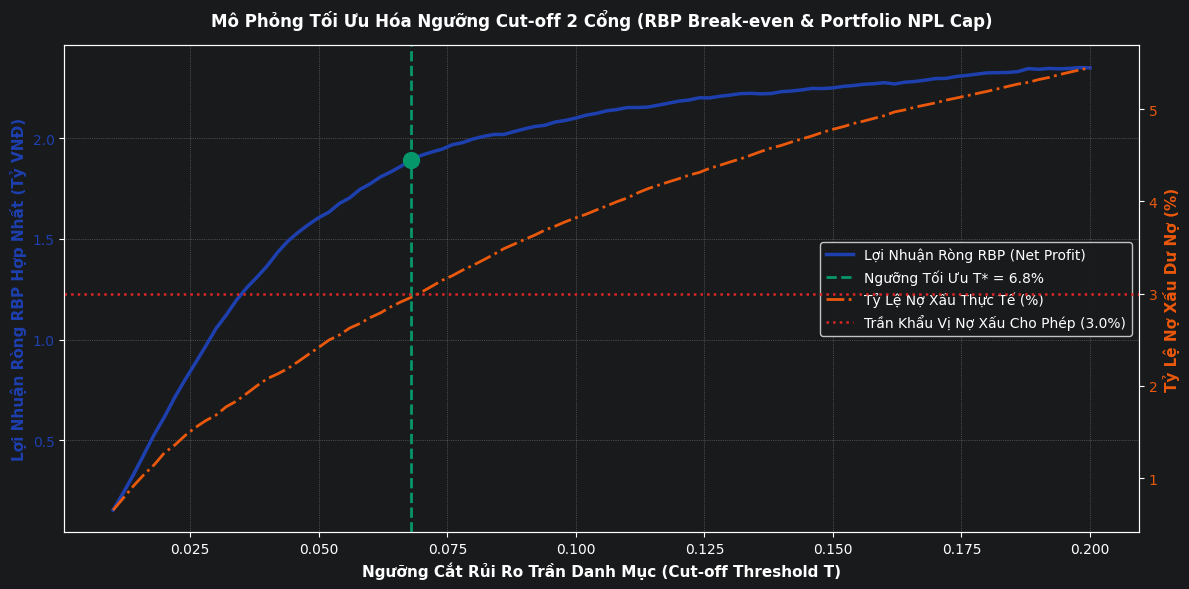

In [2]:
# ==============================================================================
# QUY TRÌNH TỐI ƯU HÓA NGƯỠNG PHÊ DUYỆT TÍN DỤNG RBP (OFFLINE OOF SIMULATION)
# Chuẩn mực áp dụng: Basel III/IV (ASRF), EBA Guidelines & NHNN Regulations
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# BƯỚC 1: TRÍCH XUẤT DỮ LIỆU ĐÁNH GIÁ NGOÀI MẪU (OUT-OF-FOLD DATA)
# ------------------------------------------------------------------------------
probs_oof = eval_output['opt_ensemble_oof']
y_true = eval_output['y'].values
df_master = eval_output['df']

N_SAMPLES = len(y_true)

# Trích xuất các trường thông tin hợp đồng thực tế
loan_amounts = (
    df_master['AMT_CREDIT'].values 
    if 'AMT_CREDIT' in df_master.columns 
    else np.full(N_SAMPLES, 100_000_000.0)
)
annuities = (
    df_master['AMT_ANNUITY'].values 
    if 'AMT_ANNUITY' in df_master.columns 
    else loan_amounts / 24.0
)
incomes = (
    df_master['AMT_INCOME_TOTAL'].values 
    if 'AMT_INCOME_TOTAL' in df_master.columns 
    else np.full(N_SAMPLES, 20_000_000.0)
)
terms = (
    df_master['TERM_MONTHS'].values 
    if 'TERM_MONTHS' in df_master.columns 
    else np.full(N_SAMPLES, 24)
)

# Tính tỷ lệ nghĩa vụ nợ trên thu nhập cơ sở (Debt-to-Income - DTI)
dti_ratios = (annuities / np.maximum(incomes, 1.0)) * 100.0

# ------------------------------------------------------------------------------
# BƯỚC 2: THIẾT LẬP HỆ THỐNG THAM SỐ ĐỊNH GIÁ & QUẢN TRỊ RỦI RO DANH MỤC
# ------------------------------------------------------------------------------
# 1. Biểu phí điều chuyển vốn nội bộ theo kỳ hạn (FTP Curve)
FTP_MAP = {
    12: 0.0520,  # 5.20%/năm (Kỳ hạn 12 tháng)
    24: 0.0560,  # 5.60%/năm (Kỳ hạn 24 tháng)
    36: 0.0600,  # 6.00%/năm (Kỳ hạn 36 tháng)
    48: 0.0640,  # 6.40%/năm (Kỳ hạn 48 tháng)
    60: 0.0680   # 6.80%/năm (Kỳ hạn 60 tháng)
}
ftp_rates = np.array([FTP_MAP.get(int(t), 0.0560) for t in terms])

# 2. Các cấu phần chi phí định mức theo chuẩn ngân hàng bán lẻ
C_OPEX = 0.0180        # Chi phí vận hành phân bổ (1.80%/năm)
LGD = 0.6500           # Tỷ lệ tổn thất khi vỡ nợ (65.00% theo chuẩn Basel Unsecured Retail)
S_CAPITAL = 0.0180     # Chi phí vốn kinh tế dự phòng rủi ro ngoài dự kiến (1.80%/năm)
M_TARGET = 0.0150      # Biên lợi nhuận ròng mục tiêu của cổ đông (1.50%/năm)

# 3. Biên độ thương mại & Khẩu vị rủi ro chính sách
R_FLOOR = 0.0850       # Sàn lãi suất cho vay thương mại (8.50%/năm)
R_CEILING = 0.2500     # Trần lãi suất cho vay tiêu dùng (25.00%/năm)
MAX_DTI_LIMIT = 50.0   # Trần tỷ lệ nghĩa vụ nợ trên thu nhập (50.0%)
MAX_PORTFOLIO_NPL = 3.0 # Trần nợ xấu danh mục theo khẩu vị rủi ro (3.00%)

# ------------------------------------------------------------------------------
# BƯỚC 3: ĐỊNH GIÁ RBP & ĐÁNH GIÁ SÀNG LỌC VI MÔ TỪNG HỒ SƠ (CỔNG 1)
# ------------------------------------------------------------------------------
# Tính lãi suất kỹ thuật theo mô hình chi phí vốn cộng dồn (Cost-Plus Pricing)
raw_rates = ftp_rates + C_OPEX + (probs_oof * LGD) + S_CAPITAL + M_TARGET
offered_rates = np.clip(raw_rates, R_FLOOR, R_CEILING)

# Tính ngưỡng xác suất vỡ nợ hòa vốn động cho từng hợp đồng (Break-even PD)
# Công thức: T*_breakeven = (r_applied - FTP - OpEx - Capital) / LGD
breakeven_pds = np.maximum(0.010, (offered_rates - ftp_rates - C_OPEX - S_CAPITAL) / LGD)

# Điều kiện qua Cổng 1: Hồ sơ có lãi (PD <= Break-even) VÀ khả năng trả nợ an toàn (DTI <= 50%)
gate1_viable = (probs_oof <= breakeven_pds) & (dti_ratios <= MAX_DTI_LIMIT)

# Lợi nhuận ròng kinh tế kỳ vọng của từng hợp đồng i (tính bằng đồng):
expected_contract_profits = loan_amounts * (
    offered_rates - ftp_rates - C_OPEX - S_CAPITAL - (y_true * LGD)
)

# ------------------------------------------------------------------------------
# BƯỚC 4: QUÉT LƯỚI TỐI ƯU HÓA TÌM NGƯỠNG CẮT TRẦN TOÀN DANH MỤC (CỔNG 2)
# ------------------------------------------------------------------------------
threshold_grid = np.arange(0.010, 0.202, 0.002) # Quét từ 1.0% đến 20.0%, bước nhảy 0.2%
sim_records = []

for T in threshold_grid:
    # Quyết định phê duyệt hợp nhất: Thỏa mãn Cổng 1 ĐỒNG THỜI PD <= Ngưỡng trần danh mục T
    approved_mask = gate1_viable & (probs_oof <= T)
    n_approved = np.sum(approved_mask)

    if n_approved > 0:
        total_profit = np.sum(expected_contract_profits[approved_mask])
        total_approved_credit = np.sum(loan_amounts[approved_mask])
        
        # Tỷ lệ nợ xấu danh mục đo lường theo tỷ trọng quy mô dư nợ (Exposure-Weighted Bad Rate)
        bad_credit = np.sum(loan_amounts[approved_mask & (y_true == 1)])
        portfolio_bad_rate = (bad_credit / total_approved_credit) * 100.0
        
        approval_rate = (n_approved / N_SAMPLES) * 100.0
    else:
        total_profit = 0.0
        portfolio_bad_rate = 0.0
        approval_rate = 0.0

    # Kiểm tra ràng buộc khẩu vị nợ xấu danh mục
    is_feasible = (portfolio_bad_rate <= MAX_PORTFOLIO_NPL) and (n_approved > 0)

    sim_records.append({
        'Threshold': round(T, 4),
        'Threshold_Pct': f"{T * 100:.1f}%",
        'Approval_Rate': approval_rate,
        'Portfolio_Bad_Rate': portfolio_bad_rate,
        'Net_Profit_Billion': total_profit / 1e9,
        'Is_Feasible': is_feasible
    })

df_sim_results = pd.DataFrame(sim_records)

# Trích xuất điểm tối ưu T*: Cực đại hóa lợi nhuận ròng trong miền ràng buộc nợ xấu <= 3.0%
feasible_space = df_sim_results[df_sim_results['Is_Feasible']]

if not feasible_space.empty:
    optimal_scenario = feasible_space.loc[feasible_space['Net_Profit_Billion'].idxmax()]
else:
    optimal_scenario = df_sim_results.loc[df_sim_results['Portfolio_Bad_Rate'].idxmin()]

print("=" * 80)
print(f"🎯 KẾT QUẢ TỐI ƯU HÓA NGƯỠNG PHÊ DUYỆT TÍN DỤNG 2 CỔNG (N={N_SAMPLES:,}):")
print("=" * 80)
print(f"🔹 Ngưỡng cắt trần tối ưu (T*)       : {optimal_scenario['Threshold_Pct']} (PD < {optimal_scenario['Threshold']:.4f})")
print(f"🔹 Tỷ lệ phê duyệt toàn danh mục    : {optimal_scenario['Approval_Rate']:.2f}%")
print(f"🔹 Tỷ lệ nợ xấu kiểm soát thực tế   : {optimal_scenario['Portfolio_Bad_Rate']:.2f}% (Ràng buộc: <= {MAX_PORTFOLIO_NPL:.1f}%)")
print(f"🔹 Tổng lợi nhuận ròng cực đại      : {optimal_scenario['Net_Profit_Billion']:,.2f} Tỷ VNĐ")
print("=" * 80)

# ------------------------------------------------------------------------------
# BƯỚC 5: TRỰC QUAN HÓA MIỀN KHẢ THI & ĐÁNH ĐỔI LỢI NHUẬN - RỦI RO
# ------------------------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 6))

color_profit = '#1E40AF' # Xanh Navy
ax1.set_xlabel('Ngưỡng Cắt Rủi Ro Trần Danh Mục (Cut-off Threshold T)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Lợi Nhuận Ròng RBP Hợp Nhất (Tỷ VNĐ)', color=color_profit, fontsize=11, fontweight='bold')
ax1.plot(df_sim_results['Threshold'], df_sim_results['Net_Profit_Billion'], 
         color=color_profit, linewidth=2.5, label='Lợi Nhuận Ròng RBP (Net Profit)')
ax1.axvline(x=optimal_scenario['Threshold'], color='#059669', linestyle='--', linewidth=2.0,
            label=f"Ngưỡng Tối Ưu T* = {optimal_scenario['Threshold_Pct']}")
ax1.scatter(optimal_scenario['Threshold'], optimal_scenario['Net_Profit_Billion'], 
            color='#059669', s=130, zorder=5)
ax1.tick_params(axis='y', labelcolor=color_profit)
ax1.grid(True, linestyle=':', alpha=0.6)

# Trục thứ 2 biểu diễn tỷ lệ nợ xấu danh mục
ax2 = ax1.twinx()
color_npl = '#EA580C' # Cam đất
ax2.set_ylabel('Tỷ Lệ Nợ Xấu Dư Nợ (%)', color=color_npl, fontsize=11, fontweight='bold')
ax2.plot(df_sim_results['Threshold'], df_sim_results['Portfolio_Bad_Rate'], 
         color=color_npl, linewidth=2.0, linestyle='-.', label='Tỷ Lệ Nợ Xấu Thực Tế (%)')
ax2.axhline(y=MAX_PORTFOLIO_NPL, color='#DC2626', linestyle=':', linewidth=1.8, 
            label=f"Trần Khẩu Vị Nợ Xấu Cho Phép ({MAX_PORTFOLIO_NPL:.1f}%)")
ax2.tick_params(axis='y', labelcolor=color_npl)

# Hợp nhất Chú giải (Legend)
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right', framealpha=0.95)

plt.title('Mô Phỏng Tối Ưu Hóa Ngưỡng Cut-off 2 Cổng (RBP Break-even & Portfolio NPL Cap)', 
          fontsize=12, fontweight='bold', pad=14)
fig.tight_layout()
plt.show()